# Web Application Performance Analysis
### Apache JMeter · Python · Experimental Design

**A reproducible analysis of historical load-test results from BlazeDemo, a demonstration flight-booking web application.**

- **24 recorded configurations**: 4 concurrency levels × 2 inter-arrival settings × 3 workload mixes
- **61,296 HTTP requests** in the captured results
- Analysis includes latency percentiles, response-time distributions, factorial effects and regression modelling

**How to read:** This notebook includes precomputed outputs so it is useful directly in GitHub's notebook viewer. To reproduce the results, install the requirements and run all cells locally. It **does not send network traffic or perform any load testing**.

> Scope: academic measurement and analysis exercise. These measurements are specific to a shared public demo service and are not production capacity benchmarks.

## 1 — Imports and data loading

Each CSV corresponds to a recorded JMeter test. Configuration parameters are encoded in its filename. All times reported below are **milliseconds**.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from IPython.display import display

root = Path.cwd()
if not (root / 'data' / 'results').exists() and (root.parent / 'data' / 'results').exists():
    root = root.parent
files = sorted((root / 'data' / 'results').glob('results_*.csv'))
assert len(files) == 24, f'Expected 24 CSV files, found {len(files)} in {root}'
rows = []
pattern = re.compile(r'results_t(\d+)_ia(\d+)_mix(\d+)-(\d+)\.csv')
for file in files:
    match = pattern.fullmatch(file.name)
    assert match, f'Unexpected filename: {file.name}'
    threads, interarrival_ms, browse_pct, purchase_pct = map(int, match.groups())
    frame = pd.read_csv(file)
    frame['threads'] = threads
    frame['interarrival_ms'] = interarrival_ms
    frame['browse_pct'] = browse_pct
    frame['purchase_pct'] = purchase_pct
    frame['configuration'] = file.stem.removeprefix('results_')
    rows.append(frame)
df = pd.concat(rows, ignore_index=True)
assert df['elapsed'].notna().all()
print(f'Loaded {len(files)} configurations and {len(df):,} request records.')

Loaded 24 configurations and 61,296 request records.


## 2 — Overall performance

The results below are **sample statistics across the recorded requests**, not a claim about future performance or server capacity.

In [2]:
metrics = pd.DataFrame([
    ('Requests', f'{len(df):,}'),
    ('Successful responses', f"{df['success'].astype(str).str.lower().eq('true').mean()*100:.1f}%"),
    ('Mean response time', f"{df['elapsed'].mean():.1f} ms"),
    ('Median response time', f"{df['elapsed'].median():.0f} ms"),
    ('95th percentile', f"{df['elapsed'].quantile(.95):.0f} ms"),
    ('99th percentile', f"{df['elapsed'].quantile(.99):.0f} ms"),
], columns=['Metric','Observed value'])
display(metrics)

,Metric,Observed value
0,Requests,"61,296"
1,Successful responses,100.0%
2,Mean response time,294.1 ms
3,Median response time,267 ms
4,95th percentile,428 ms
5,99th percentile,738 ms


## 3 — Per-configuration summary

Each cell represents a different combination of concurrent users, inter-arrival parameter and browsing/purchase workload mixture.

In [3]:
grp = df.groupby(['threads','interarrival_ms','browse_pct'], as_index=False)
summary = grp['elapsed'].agg(['count','mean','median','std',lambda a: a.quantile(.95)]).rename(columns={'<lambda_0>':'p95'})
summary['purchase_pct'] = 100 - summary['browse_pct']
summary = summary.sort_values(['threads','interarrival_ms','browse_pct']).reset_index(drop=True)
display(summary.round({'mean':1,'median':1,'std':1,'p95':1}))

,threads,interarrival_ms,browse_pct,count,mean,median,std,p95,purchase_pct
0,10,500,0,74,363.1,317.0,138.5,540.9,100
1,10,500,50,510,338.2,310.5,104.8,517.8,50
2,10,500,100,439,344.1,301.0,129.9,555.5,0
3,10,1000,0,69,288.4,270.0,55.3,361.2,100
4,10,1000,50,323,281.3,263.0,70.4,363.7,50
5,10,1000,100,258,275.5,264.0,44.9,332.7,0
6,50,500,0,365,289.7,271.0,80.1,365.4,100
7,50,500,50,2641,289.1,264.0,111.3,377.0,50
8,50,500,100,2299,289.7,258.0,151.4,388.1,0
9,50,1000,0,338,285.6,268.0,71.5,364.3,100


## 4 — Response time vs concurrent users

For clarity, the figure below uses the **50% browse / 50% purchase** workload mixture and compares the two inter-arrival settings. Be cautious about attributing differences entirely to concurrency: this is a shared, externally hosted demo service.

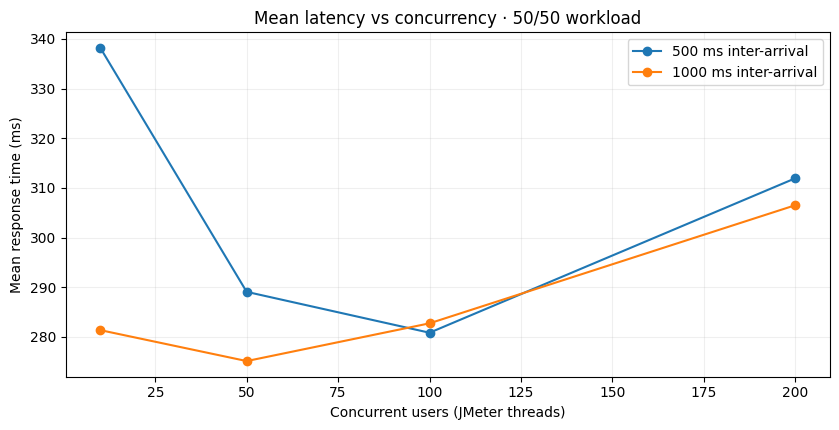

In [4]:
subset = summary[summary['browse_pct'] == 50]
fig, ax = plt.subplots(figsize=(8.5,4.4))
for arrival, values in subset.groupby('interarrival_ms'):
    values = values.sort_values('threads')
    ax.plot(values['threads'], values['mean'], marker='o', label=f'{arrival} ms inter-arrival')
ax.set(xlabel='Concurrent users (JMeter threads)', ylabel='Mean response time (ms)', title='Mean latency vs concurrency · 50/50 workload')
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(root/'assets/response-time-vs-threads.png',dpi=140)
plt.show()

## 5 — Tail latency (p95)

An average can hide slower requests. The 95th percentile shows a more conservative view of responsiveness.

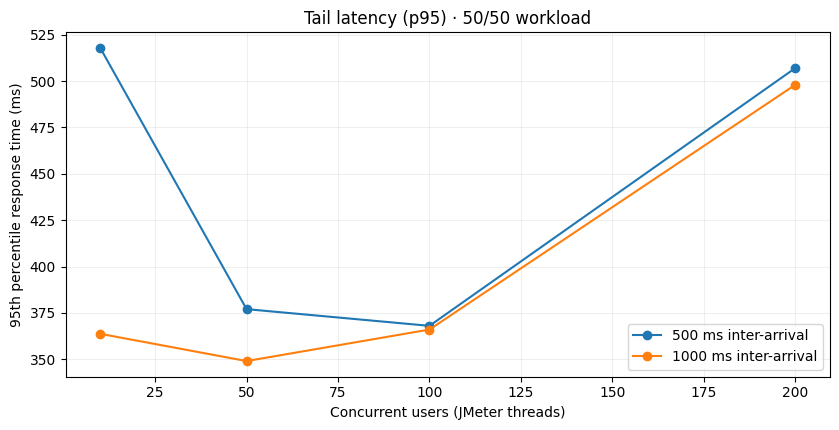

In [5]:
fig, ax = plt.subplots(figsize=(8.5,4.4))
for arrival, values in subset.groupby('interarrival_ms'):
    values = values.sort_values('threads')
    ax.plot(values['threads'], values['p95'], marker='o', label=f'{arrival} ms inter-arrival')
ax.set(xlabel='Concurrent users (JMeter threads)', ylabel='95th percentile response time (ms)', title='Tail latency (p95) · 50/50 workload')
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.savefig(root/'assets/p95-vs-threads.png',dpi=140)
plt.show()

## 6 — Distribution and normality

Example configuration: **10 threads**, **500 ms inter-arrival**, **0% browse / 100% purchase**. We use a Shapiro–Wilk test as a diagnostic, without assuming all web latency measurements follow a Gaussian distribution.

Number of requests: 74 | Mean: 363.1 ms | Shapiro–Wilk p-value: 1.89e-11


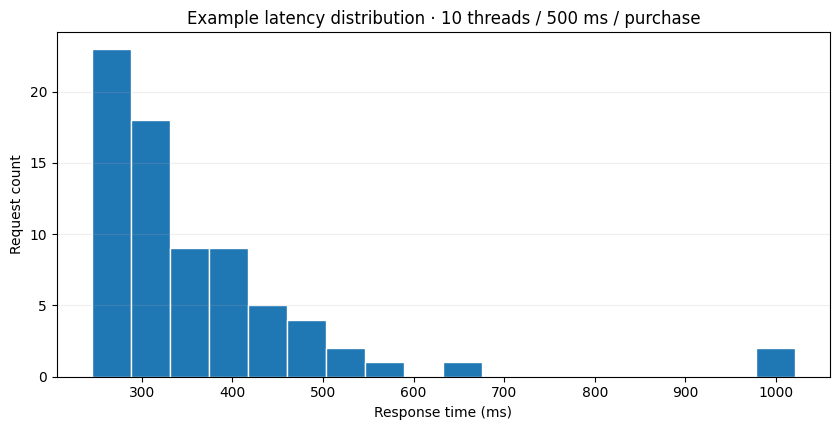

In [6]:
sample = df[(df.threads == 10) & (df.interarrival_ms == 500) & (df.browse_pct == 0)]['elapsed']
shapiro = stats.shapiro(sample.to_numpy())
print(f'Number of requests: {len(sample)} | Mean: {sample.mean():.1f} ms | Shapiro–Wilk p-value: {shapiro.pvalue:.2e}')
fig, ax = plt.subplots(figsize=(8.5,4.4))
ax.hist(sample, bins=18, edgecolor='white')
ax.set(xlabel='Response time (ms)', ylabel='Request count', title='Example latency distribution · 10 threads / 500 ms / purchase')
ax.grid(axis='y',alpha=.2)
plt.tight_layout()
plt.savefig(root/'assets/latency-distribution.png',dpi=140)
plt.show()

## 7 — 2³ factorial design (extreme factor levels)

For the factorial comparison we use the eight configurations formed by:

- **A:** 10 vs 200 threads
- **B:** 500 vs 1,000 ms inter-arrival
- **C:** 100% browsing vs 100% purchase

Each effect is calculated as the difference between the **mean response time at the high and low level**, averaging the four relevant configuration means. This is exploratory: there is only one recorded run per extreme configuration and uncontrolled network/server variability.

,Mean response-time difference (ms)
Threads (200 − 10),-26.29
Inter-arrival (1000 − 500 ms),-36.70
Purchase mix (100% − 0%),2.30


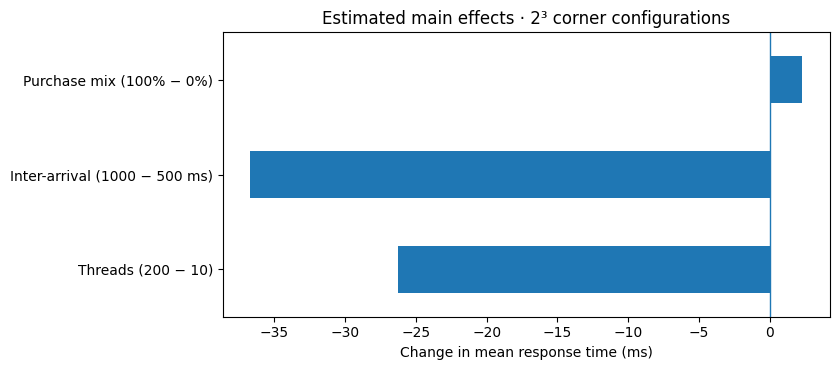

In [7]:
corners = summary[(summary.threads.isin([10,200])) &
                  (summary.interarrival_ms.isin([500,1000])) &
                  (summary.browse_pct.isin([0,100]))].copy()
assert len(corners) == 8
factors = {
  'Threads (200 − 10)': corners.loc[corners.threads==200,'mean'].mean() - corners.loc[corners.threads==10,'mean'].mean(),
  'Inter-arrival (1000 − 500 ms)': corners.loc[corners.interarrival_ms==1000,'mean'].mean() - corners.loc[corners.interarrival_ms==500,'mean'].mean(),
  'Purchase mix (100% − 0%)': corners.loc[corners.purchase_pct==100,'mean'].mean() - corners.loc[corners.purchase_pct==0,'mean'].mean(),
}
effects = pd.Series(factors,name='Mean response-time difference (ms)')
display(effects.to_frame().round(2))
fig, ax = plt.subplots(figsize=(8.5,3.8))
effects.plot.barh(ax=ax)
ax.axvline(0,linewidth=1)
ax.set(xlabel='Change in mean response time (ms)',title='Estimated main effects · 2³ corner configurations')
plt.tight_layout()
plt.savefig(root/'assets/factor-effects.png',dpi=140)
plt.show()

## 8 — Exploratory regression on configuration means

We compare two models on the **24 configuration-level mean response times**. The figures are **in-sample** fits, not cross-validated performance and should not be interpreted as production-grade forecasting.

In [8]:
y = summary['mean'].to_numpy()
X_linear = summary[['threads','interarrival_ms','purchase_pct']].to_numpy()
X_enhanced = np.column_stack([
    np.log(summary['threads']),
    np.square(summary['threads']),
    1 / summary['interarrival_ms'],
    summary['purchase_pct'] / 100,
])
model_comparison = []
for name, features in [('Linear baseline',X_linear), ('Transformed model',X_enhanced)]:
    model = LinearRegression().fit(features, y)
    pred = model.predict(features)
    model_comparison.append({'Model':name, 'In-sample R²':r2_score(y,pred), 'In-sample RMSE (ms)':np.sqrt(mean_squared_error(y,pred))})
display(pd.DataFrame(model_comparison).round(3))

,Model,In-sample R²,In-sample RMSE (ms)
0,Linear baseline,0.218,20.204
1,Transformed model,0.548,15.357


## 9 — Key takeaways and limitations

**Observed within the dataset**

- All 61,296 recorded requests were marked successful (HTTP 200).
- The overall mean response time was about **294 ms**, with **p95 ≈ 428 ms**.
- Factorial contrasts indicate that inter-arrival spacing and thread count matter more than the browse/purchase mix **within the eight corner configurations**.
- Request latencies are skewed; relying on the average alone hides tail behaviour.

**Important limitations**

- BlazeDemo is a shared third-party demonstration system; workload from other visitors and network variability could affect observations.
- Tests were recorded from one client environment without controlled server-side monitoring or independent replications.
- Factor contrasts and regression are **descriptive/exploratory**, not verified causal estimates or production capacity guarantees.
- **Do not re-run load tests against external services without explicit permission.** The included JMeter plan is an archived academic artefact. Reproducing this notebook requires no network requests.

**Project artefacts:** [JMeter plan](../jmeter/blazedemo_test_plan.jmx) · [Analysis script](../scripts/analyze_results.py) · [Raw CSV data](../data/results/)